In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# Objective: We will build a graph, that will 
# - take our user query.
# - Do a web search for it. 
# - Return the summary of web search

In [3]:
# Lets how Tavily gets called
from langchain_community.tools import TavilySearchResults

searchTool = TavilySearchResults(max_results = 5)

user_query = "Details of FIR againt Manish Sisodhiya in connection with the Delhi Excise Policy case"


search_results = searchTool.invoke(user_query)
search_results

C:\Users\sneh.lata\AppData\Local\Temp\ipykernel_24144\1007108006.py:4: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  searchTool = TavilySearchResults(max_results = 5)


[{'title': '2022 Delhi liquor policy case - Wikipedia',
  'url': 'https://en.wikipedia.org/wiki/2022_Delhi_liquor_policy_case',
  'content': '2022 Delhi liquor policy case - Wikipedia The **Delhi Liquor Scam** is an alleged political scandal concerning the Delhi Government, which paved its way through the introduction of Delhi\'s Excise Policy from 2021 to 2022. In February 2021, a Group of Ministers led by Deputy Chief Minister Manish Sisodia and Health Minister Satyendra Kumar Jain was organised to look into reforms to the Delhi excise policy, which constituted a committee of experts. 3.   **^**"Delhi Excise Policy | Aam Aadmi Party alleges \'corruption\' in change of decision by Centre\'s LG; seeks CBI probe". **^**"Delhi excise policy case: Timeline of how Manish Sisodia landed in jail". ^ Jump up to: _**a**__**b**_"ED gets nod to prosecute Arvind Kejriwal, Manish Sisodia in liquor policy case".',
  'score': 0.98577},
 {'title': 'Supreme Court grants bail to Manish Sisodia in Delhi

In [4]:
# You will want to format the Tavily result so that it can be passed on to LLM as a long string
    

formatted_search_docs = "\n\n---\n\n".join(
    [
        f'<Document href = "{doc["url"]}">\n{doc["content"]}\n</Document>'
        for doc in search_results
    ]
)

print(formatted_search_docs)

<Document href = "https://en.wikipedia.org/wiki/2022_Delhi_liquor_policy_case">
2022 Delhi liquor policy case - Wikipedia The **Delhi Liquor Scam** is an alleged political scandal concerning the Delhi Government, which paved its way through the introduction of Delhi's Excise Policy from 2021 to 2022. In February 2021, a Group of Ministers led by Deputy Chief Minister Manish Sisodia and Health Minister Satyendra Kumar Jain was organised to look into reforms to the Delhi excise policy, which constituted a committee of experts. 3.   **^**"Delhi Excise Policy | Aam Aadmi Party alleges 'corruption' in change of decision by Centre's LG; seeks CBI probe". **^**"Delhi excise policy case: Timeline of how Manish Sisodia landed in jail". ^ Jump up to: _**a**__**b**_"ED gets nod to prosecute Arvind Kejriwal, Manish Sisodia in liquor policy case".
</Document>

---

<Document href = "https://www.thehindu.com/news/national/manish-sisodia-secures-bail-in-both-ed-and-cbi-cases-on-delhi-excise-policy/ar

In [5]:
# Next job

# Pass the questions (maybe reformatted) and search result to the LLM through a prompt

prompt_template = """
You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. If you don't know the answer, just say that you don't know. Keep your answer. Preferably provide answer in bullet points  with datewise events which lead to his arrest.
Question: {question} 
Context: {context} 
Answer:
"""

prompt = prompt_template.format(
    context = formatted_search_docs,
    question = "Why was Manish Sisodhiya arrested?"
)

print(prompt)
# This is what get passed to LLM. LLMs job is simply to analyze your prompt (which has the questio, and the context) and generate report in your desired format.


You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. If you don't know the answer, just say that you don't know. Keep your answer. Preferably provide answer in bullet points  with datewise events which lead to his arrest.
Question: Why was Manish Sisodhiya arrested? 
Context: <Document href = "https://en.wikipedia.org/wiki/2022_Delhi_liquor_policy_case">
2022 Delhi liquor policy case - Wikipedia The **Delhi Liquor Scam** is an alleged political scandal concerning the Delhi Government, which paved its way through the introduction of Delhi's Excise Policy from 2021 to 2022. In February 2021, a Group of Ministers led by Deputy Chief Minister Manish Sisodia and Health Minister Satyendra Kumar Jain was organised to look into reforms to the Delhi excise policy, which constituted a committee of experts. 3.   **^**"Delhi Excise Policy | Aam Aadmi Party alleges 'corruption' in change of decision by Centre's LG; seeks CBI probe

In [6]:
# Lets see what LLM gives out

from langchain.chat_models import init_chat_model
llm = init_chat_model("llama3-8b-8192", model_provider="groq")

In [7]:
response = llm.invoke(prompt)
response

AIMessage(content='Based on the provided context, here is the answer to the question:\n\nManish Sisodia was arrested on February 26, 2023, by the CBI for alleged corruption in the formulation and implementation of the Delhi Excise Policy.\n\nHere are the key events leading to his arrest in bullet points:\n\n• February 2021: A Group of Ministers led by Deputy Chief Minister Manish Sisodia and Health Minister Satyendra Kumar Jain was formed to look into reforms to the Delhi excise policy.\n• 2021-2022: The Delhi Excise Policy was introduced, and Manish Sisodia was involved in its formulation and implementation.\n• February 26, 2023: Manish Sisodia was arrested by the CBI for alleged corruption in the Delhi Excise Policy case.\n• After his arrest, Sisodia moved multiple bail applications at trial courts, the Delhi High Court, and the Supreme Court, which were eventually granted, and he was released on bail.\n\nNote: The context does not provide specific details on why Manish Sisodia was a

In [8]:
print(response.content)

Based on the provided context, here is the answer to the question:

Manish Sisodia was arrested on February 26, 2023, by the CBI for alleged corruption in the formulation and implementation of the Delhi Excise Policy.

Here are the key events leading to his arrest in bullet points:

• February 2021: A Group of Ministers led by Deputy Chief Minister Manish Sisodia and Health Minister Satyendra Kumar Jain was formed to look into reforms to the Delhi excise policy.
• 2021-2022: The Delhi Excise Policy was introduced, and Manish Sisodia was involved in its formulation and implementation.
• February 26, 2023: Manish Sisodia was arrested by the CBI for alleged corruption in the Delhi Excise Policy case.
• After his arrest, Sisodia moved multiple bail applications at trial courts, the Delhi High Court, and the Supreme Court, which were eventually granted, and he was released on bail.

Note: The context does not provide specific details on why Manish Sisodia was arrested, but it mentions alleg

In [12]:
# Create a node for Tavily Search

import operator
from typing import Annotated
from typing_extensions import TypedDict

class State(TypedDict):
    searchQuery: str
    searchReport: str
    context: Annotated[list, operator.add]
    

def search_web(state):
    """Retrieve Docs from web search"""
    tavily_search = TavilySearchResults(max_results = 5)
    search_result = tavily_search.invoke(state['searchQuery'])
    
     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'<Document href="{doc["url"]}">\n{doc["content"]}\n</Document>'
            for doc in search_result
        ]
    )

    return {"context": [formatted_search_docs]}
    
    

In [13]:
testState = State(
    searchQuery="Member of Parliament from Gautam Budh Nagar, Uttar Pradesh"
)

search_web(testState)

{'context': ['<Document href="https://en.wikipedia.org/wiki/Gautam_Buddha_Nagar_Lok_Sabha_constituency">\n| Gautam Buddha Nagar  UP-13 | |\n| --- | --- |\n| Lok Sabha constituency | |\n| Interactive Map Outlining Gautam Buddha Nagar Lok Sabha constituency | |\n| Constituency details | |\n| Country | India |\n| Region | North India |\n| State | Uttar Pradesh |\n| Assembly constituencies | Noida Dadri Jewar Sikandrabad Khurja |\n| Established | 2008-present |\n| Total electors | 26,74,938 |\n| Reservation | None |\n| Member of Parliament | |\n| 18th Lok Sabha | |\n|  | |\n| Incumbent Mahesh Sharma | | [...] | No | Name | District | Member | Party | | 2024 Lead | |\n| --- | --- | --- | --- | --- | --- | --- | --- |\n| 61 | Noida | Gautam Buddh Nagar | Pankaj Singh "Pankaj Singh (politician)") |  | Bharatiya Janata Party |  | Bharatiya Janata Party |\n| 62 | Dadri | Tejpal Singh Nagar |\n| 63 | Jewar | Dhirendra Singh |\n| 64 | Sikandrabad | Bulandshahr | Lakshmi Raj Singh |\n| 70 | Khurja

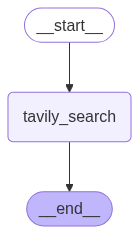

In [11]:

#invoke it as a graph
from IPython.display import Image, display

from typing import Any
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

# Add nodes
builder = StateGraph(State)

# Initialize each node with node_secret 
builder.add_node("tavily_search", search_web)

# Flow
builder.add_edge(START, "tavily_search")
builder.add_edge("tavily_search", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
testState = graph.invoke(testState)

In [17]:
testState

{'searchQuery': 'Member of Parliament from Gautam Budh Nagar, Uttar Pradesh',
 'context': ['<Document href="https://en.wikipedia.org/wiki/Gautam_Buddha_Nagar_Lok_Sabha_constituency">\n| Gautam Buddha Nagar  UP-13 | |\n| --- | --- |\n| Lok Sabha constituency | |\n| Interactive Map Outlining Gautam Buddha Nagar Lok Sabha constituency | |\n| Constituency details | |\n| Country | India |\n| Region | North India |\n| State | Uttar Pradesh |\n| Assembly constituencies | Noida Dadri Jewar Sikandrabad Khurja |\n| Established | 2008-present |\n| Total electors | 26,74,938 |\n| Reservation | None |\n| Member of Parliament | |\n| 18th Lok Sabha | |\n|  | |\n| Incumbent Mahesh Sharma | | [...] | No | Name | District | Member | Party | | 2024 Lead | |\n| --- | --- | --- | --- | --- | --- | --- | --- |\n| 61 | Noida | Gautam Buddh Nagar | Pankaj Singh "Pankaj Singh (politician)") |  | Bharatiya Janata Party |  | Bharatiya Janata Party |\n| 62 | Dadri | Tejpal Singh Nagar |\n| 63 | Jewar | Dhirendra 

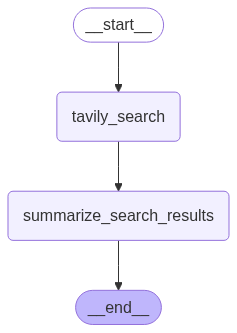

In [19]:
#build graph
#invoke it as a graph
from IPython.display import Image, display

from typing import Any
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

# create a node for tavily search

class State(TypedDict):
    websearchInstructions: str
    questionForReportGeneration: str
    report: str
    context: Annotated[list, operator.add]

def search_web(state):
    
    """ Retrieve docs from web search """

    # Search
    tavily_search = TavilySearchResults(max_results=5)
    search_docs = tavily_search.invoke(state['websearchInstructions'])

     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'<Document href="{doc["url"]}">\n{doc["content"]}\n</Document>'
            for doc in search_docs
        ]
    )

    return {"context": [formatted_search_docs]} 


def generate_answer(state):
    
    """ Node to answer a question """

    # Get state
    context = state["context"]
    question = state["questionForReportGeneration"]
    
    prompt_template = """
    You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question. If you don't know the answer, just say that you don't know. Use three sentences maximum and keep the answer concise.
    Question: {question} 
    Context: {context} 
    Answer:
    """

    prompt = prompt_template.format(question=question, context=context)    
    
    # Answer
    llm_response = llm.invoke(prompt)
      
    # Append it to state
    return {"report": llm_response.content}


#build graph
#invoke it as a graph
from IPython.display import Image, display

from typing import Any
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END


# Add nodes
builder = StateGraph(State)

# Initialize each node with node_secret 
builder.add_node("tavily_search", search_web)
builder.add_node("summarize_search_results", generate_answer)


# Flow
builder.add_edge(START, "tavily_search")
builder.add_edge("tavily_search", "summarize_search_results")
builder.add_edge("summarize_search_results",END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
# lets invoke the graph
state = {
    "websearchInstructions": "Chief Minister of Delhi",
    "questionForReportGeneration": "Who was the chief Minister of delhi before the current Chief Minister?"
}
state = graph.invoke(state)

state

{'websearchInstructions': 'Chief Minister of Delhi',
 'questionForReportGeneration': 'Who was the chief Minister of delhi before the current Chief Minister?',
 'report': 'The Chief Minister of Delhi before Rekha Gupta was Atishi Marlena Singh, who served from September 17, 2024, to February 20, 2025.',
 'context': ['<Document href="https://www.jagranjosh.com/general-knowledge/delhi-chief-ministers-cm-list-party-name-and-tenure-1726561886-1">\nRekha Gupta of the Bharatiya Janata Party (BJP) has been declared the new Chief Minister of Delhi. This announcement on February 19, 2025, marks the BJP\'s return to power in Delhi after 27 years, with the party securing 48 out of 70 assembly seats.\n\nGupta, previously the General Secretary of the Delhi BJP and a former president of the Delhi University Students\' Union, won the Shalimar Bagh constituency. Her swearing-in ceremony is scheduled for February 20, 2025, at Ramlila Maidan. [...] Delhi Chief Ministers:Rekha Gupta is the 9th Chief Minis